# 01 · Exploring DOT contract outcomes

Every federal contract action is reported to FPDS and published on USAspending. This project follows
**Department of Transportation** contracts (FAA, FHWA, MARAD, ...) signed in FY2013-FY2023 through to the end of
FY2026, and asks what predicts how a contract *changes after it is signed*: how often it is modified, how much its
ceiling grows, how soon the first increase arrives, and whether it gets terminated.

This notebook looks at the raw shape of each outcome, since that shape is what decides the model family in the
later notebooks.

In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.features import load_awards, load_monthly, model_frame

sns.set_theme(style="whitegrid", context="notebook")
FIG = "../reports/figures/"
awards = model_frame(load_awards())
monthly = load_monthly()
print(f"{len(awards):,} awards, {awards['office'].nunique()} contracting offices, "
      f"{awards['base_fiscal_year'].min()}-{awards['base_fiscal_year'].max()}")

60,613 awards, 70 contracting offices, 2013-2023


## What the awards look like

In [2]:
display(awards["sub_agency"].value_counts(normalize=True).round(3).to_frame("share of awards"))
display(awards["pricing"].value_counts(normalize=True).round(3).to_frame("share of awards"))
display(awards[["initial_ceiling", "planned_days", "offers"]].describe(percentiles=[.1, .5, .9]).round(0))

,share of awards
sub_agency,
FAA,0.554
FHWA,0.147
MARAD,0.116
OST,0.075
other,0.051
NHTSA,0.033
FTA,0.025


,share of awards
pricing,
firm_fixed,0.789
time_materials,0.106
cost_reimbursement,0.100
fixed_other,0.005


,initial_ceiling,planned_days,offers
count,6.061300e+04,60613.0,46930.0
mean,2.113469e+06,413.0,3.0
std,1.048814e+08,505.0,4.0
min,2.500000e+04,1.0,0.0
10%,3.286200e+04,35.0,1.0
50%,1.237920e+05,296.0,2.0
90%,1.284208e+06,1095.0,6.0
max,2.000000e+10,8766.0,50.0


## Outcome 1: number of modifications

A count with a mean around 3 but a variance near 50, plus a large block of zeros. That is heavy
overdispersion, so a Poisson model's variance = mean assumption will fail. Notebook 02 tests this formally.

mean=3.06  variance=54.0  zeros=34.7%


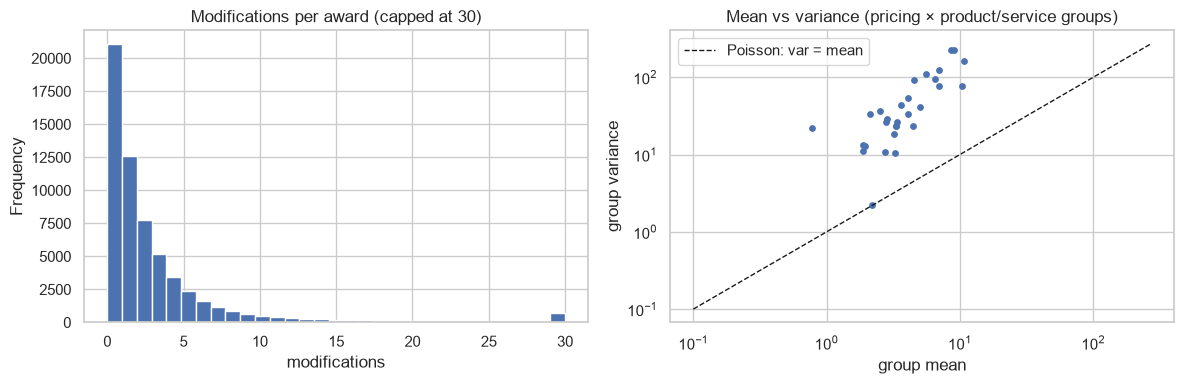

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
awards["n_mods"].clip(upper=30).plot.hist(bins=31, ax=ax[0])
ax[0].set(title="Modifications per award (capped at 30)", xlabel="modifications")
print(f"mean={awards['n_mods'].mean():.2f}  variance={awards['n_mods'].var():.1f}  "
      f"zeros={(awards['n_mods'] == 0).mean():.1%}")

# Variance-to-mean by pricing type: if Poisson held, these points would sit on the 45-degree line.
vm = awards.groupby(["pricing", "psc_group"])["n_mods"].agg(["mean", "var", "size"])
vm = vm[vm["size"] >= 50]
ax[1].scatter(vm["mean"], vm["var"], s=15)
lim = [0.1, vm["var"].max() * 1.2]
ax[1].plot(lim, lim, "k--", lw=1, label="Poisson: var = mean")
ax[1].set(xscale="log", yscale="log", xlabel="group mean", ylabel="group variance",
          title="Mean vs variance (pricing × product/service groups)")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG + "01_mods_overdispersion.png", dpi=120); plt.show()

## Outcome 2: ceiling growth

Growth ratio = final ceiling (base plus all options, after every modification) ÷ ceiling at signing.
It has three regimes: about half of awards never change (ratio exactly 1), about a fifth shrink (descoping or
de-obligation), and about a quarter grow, some by a lot. A single continuous distribution cannot describe a spike
at 1 with long tails on both sides, which is why notebook 03 uses a two-part model.

,share
growth_ratio,
unchanged,0.531
grew,0.271
shrank,0.198


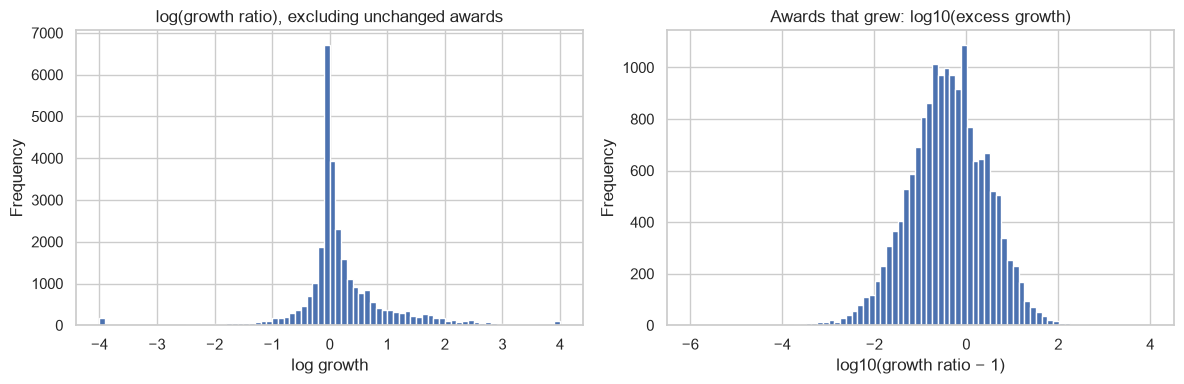

In [4]:
regime = pd.cut(awards["growth_ratio"], [0, 0.999, 1.001, np.inf], labels=["shrank", "unchanged", "grew"])
display(regime.value_counts(normalize=True).round(3).to_frame("share"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
awards.loc[awards["growth_ratio"] != 1, "log_growth"].clip(-4, 4).plot.hist(bins=80, ax=ax[0])
ax[0].set(title="log(growth ratio), excluding unchanged awards", xlabel="log growth")
grew = awards[awards["any_growth"] == 1]
np.log10(grew["growth_ratio"] - 1).plot.hist(bins=80, ax=ax[1])
ax[1].set(title="Awards that grew: log10(excess growth)", xlabel="log10(growth ratio − 1)")
plt.tight_layout(); plt.savefig(FIG + "01_growth_distribution.png", dpi=120); plt.show()

In [5]:
by = (awards.groupby("pricing")
      .agg(awards=("log_growth", "size"), share_grew=("any_growth", "mean"),
           p90_growth=("growth_ratio", lambda s: s.quantile(.9)), mean_mods=("n_mods", "mean"))
      .sort_values("share_grew"))
by.round(3)

,awards,share_grew,p90_growth,mean_mods
pricing,,,,
firm_fixed,47805,0.242,1.473,2.261
fixed_other,327,0.284,1.837,4.202
cost_reimbursement,6077,0.379,3.741,4.088
time_materials,6404,0.400,3.245,7.996


Cost-reimbursement and time-and-materials awards grow far more often than firm-fixed-price ones. That fits how
these contract types work (the government carries the cost risk), but those types also cluster in particular
services and offices. Notebooks 03-04 separate these effects.

## Outcome 3: time to the first ceiling increase

About 30% of awards have an increase of at least 1% of their initial ceiling before their work ends. Awards that
end (or are still running at the data cutoff) without one are *censored*, not "never". Notebook 07 handles this.

event rate: 28.4%


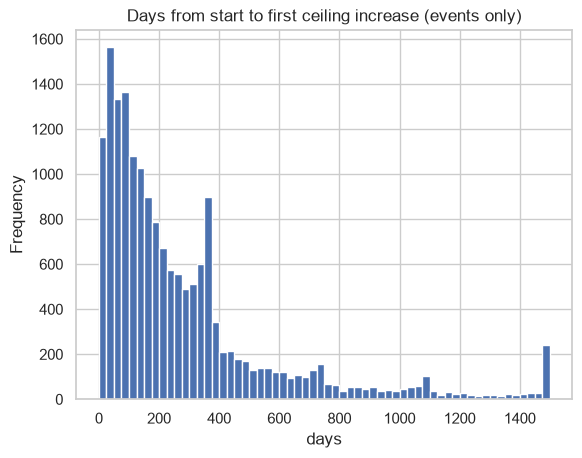

In [6]:
print(f"event rate: {awards['increase_event'].mean():.1%}")
awards.loc[awards["increase_event"] == 1, "increase_days"].clip(upper=1500).plot.hist(bins=60)
plt.title("Days from start to first ceiling increase (events only)"); plt.xlabel("days"); plt.show()

## Outcome 4: terminations, and the FY2025 wave

DOT records roughly 10-100 terminations for convenience a year. FY2025 has several times that. Notebook 05 asks
which active contracts were terminated in that year.

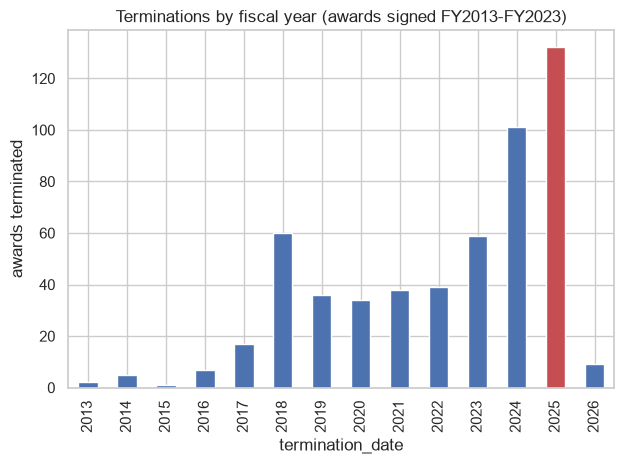

In [7]:
term = awards[awards["terminated"]]
counts = term["termination_date"].pipe(lambda d: d.dt.year + (d.dt.month >= 10)).value_counts().sort_index()
counts.plot.bar(color=["C3" if fy == 2025 else "C0" for fy in counts.index])
plt.title("Terminations by fiscal year (awards signed FY2013-FY2023)"); plt.ylabel("awards terminated")
plt.tight_layout(); plt.savefig(FIG + "01_terminations.png", dpi=120); plt.show()

## The fiscal-year-end rush

Unspent one-year money expires on 30 September, so obligations pile up in September. This is the seasonality that
notebook 06 forecasts.

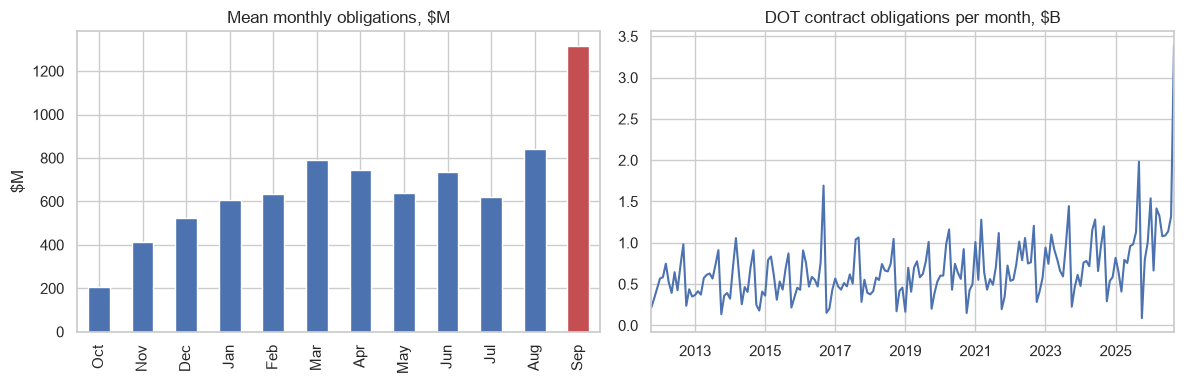

September share of annual obligations: 16.3% (an even spread would be 8.3%)


In [8]:
season = monthly.groupby("fiscal_month")[["obligations", "new_awards"]].mean()
season.index = ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(season["obligations"] / 1e6).plot.bar(ax=ax[0], color=["C0"] * 11 + ["C3"])
ax[0].set(title="Mean monthly obligations, $M", ylabel="$M")
(monthly.set_index("month")["obligations"] / 1e9).plot(ax=ax[1])
ax[1].set(title="DOT contract obligations per month, $B", xlabel="")
plt.tight_layout(); plt.savefig(FIG + "01_fy_end_rush.png", dpi=120); plt.show()

print(f"September share of annual obligations: "
      f"{monthly.loc[monthly['fiscal_month'] == 12, 'obligations'].sum() / monthly['obligations'].sum():.1%} "
      f"(an even spread would be 8.3%)")

Do contracts signed in the September rush perform worse? In the raw data, barely: their growth and modification
rates are within a point or two of other months. The models below test this with controls.

In [9]:
awards.groupby("september")[["any_growth", "n_mods", "terminated", "increase_event"]].mean().round(3)

,any_growth,n_mods,terminated,increase_event
september,,,,
0,0.275,3.034,0.008,0.287
1,0.262,3.162,0.011,0.273
